In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import warnings
import pandas as pd
import pickle
import time
import os

In [19]:
start=1000
file1 = './Samples/beta.csv'
file2 = './Samples/gamma.csv'
file3 = './Samples/sigma.csv'
beta = pd.read_csv(file1,header=None,skiprows=1).values[start:]
gamma = pd.read_csv(file2,header=None,skiprows=1).values[start:]
sigma = pd.read_csv(file3,header=None,skiprows=1).values[start:]

C:\Users\Jayson Cortez\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Jayson Cortez\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Jayson Cortez\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


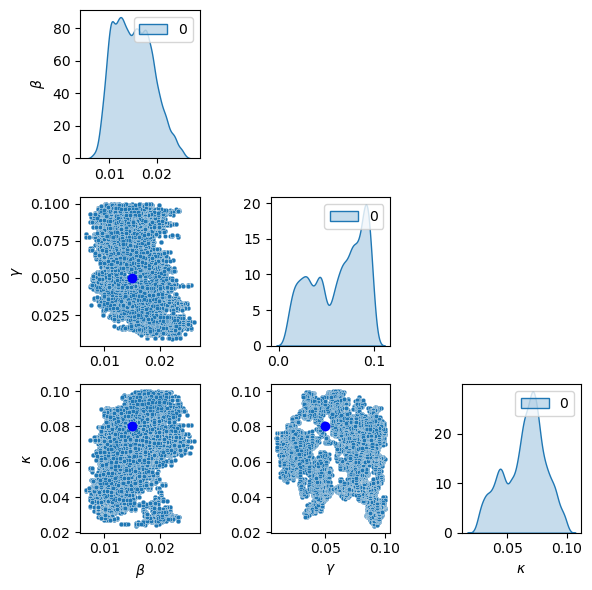

In [3]:
f,axes = plt.subplots(3,3,figsize=(6,6))
sns.kdeplot(beta,fill=True,ax=axes[0,0])
sns.kdeplot(gamma,fill=True,ax=axes[1,1])
sns.kdeplot(sigma,fill=True,ax=axes[2,2])
axes[1,0].scatter(beta,gamma,s=10,edgecolors='w',linewidth=0.2)
axes[2,0].scatter(beta,sigma,s=10,edgecolors='w',linewidth=0.2)
axes[2,1].scatter(gamma,sigma,s=10,edgecolors='w',linewidth=0.2)

colors = ['b','r','lime']

    
betas = [0.015, 0.0644, 0.0543]
sigmas = [0.08, 0.2628, 0.5508]
gammas = [0.05, 0.0772, 0.4988]

i=0
axes[1,0].scatter([betas[i]],[gammas[i]],color=colors[i])
axes[2,0].scatter([betas[i]],[sigmas[i]],color=colors[i])
axes[2,1].scatter([gammas[i]],[sigmas[i]],color=colors[i])

for i in range(3):
    for j in range(3):
        if j>i:
            axes[i,j].set_axis_off()
        if i==j:
            axes[i,j].set_ylabel(' ')
            
axes[0,0].set_ylabel(r'$\beta$')
axes[1,0].set_ylabel(r'$\gamma$')
axes[2,0].set_ylabel(r'$\kappa$')
axes[2,0].set_xlabel(r'$\beta$')
axes[2,1].set_xlabel(r'$\gamma$')
axes[2,2].set_xlabel(r'$\kappa$')

plt.tight_layout()

In [23]:
import arviz as az
beta_hdi = az.hdi(beta, hdi_prob=0.95)
gamma_hdi = az.hdi(gamma, hdi_prob=0.95)
sigma_hdi = az.hdi(sigma, hdi_prob=0.95)

print("Beta 95% HDI :", beta_hdi)
print("Gamma 95% HDI:", gamma_hdi)
print("Sigma 95% HDI:", sigma_hdi)

Beta 95% HDI : [[0.00812151 0.0222967 ]]
Gamma 95% HDI: [[0.01566291 0.09910132]]
Sigma 95% HDI: [[0.02973961 0.0936959 ]]


C:\Users\Jayson Cortez\AppData\Local\Temp\ipykernel_17704\1114194646.py:2: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  beta_hdi = az.hdi(beta, hdi_prob=0.95)
C:\Users\Jayson Cortez\AppData\Local\Temp\ipykernel_17704\1114194646.py:3: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  gamma_hdi = az.hdi(gamma, hdi_prob=0.95)
C:\Users\Jayson Cortez\AppData\Local\Temp\ipykernel_17704\1114194646.py:4: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  sigma_hdi = az.hdi(sigma, hdi_prob=0.95)


In [10]:
print('mean beta',np.mean(beta))
print('mean gamma',np.mean(gamma))
print('mean sigma',np.mean(sigma))

mean beta 0.014964456430029917
mean gamma 0.06157190475497746
mean sigma 0.06466410009845179


C:\Users\Jayson Cortez\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Jayson Cortez\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Jayson Cortez\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


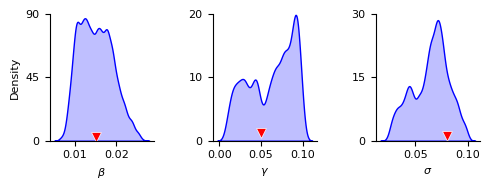

In [12]:
# Ensure 1D and remove any inf/-inf

beta_kde = pd.Series(beta.flatten()).replace([np.inf, -np.inf], np.nan).dropna()
gamma_kde = pd.Series(gamma.flatten()).replace([np.inf, -np.inf], np.nan).dropna()
sigma_kde = pd.Series(sigma.flatten()).replace([np.inf, -np.inf], np.nan).dropna()

# Colors for the KDEs
colors = ['b', 'b', 'b']
fontsiz= 8
# Create 1x3 subplot
fig, axes = plt.subplots(1, 3, figsize=(5, 2))

# Plot KDEs
sns.kdeplot(beta_kde, fill=True, ax=axes[0], color=colors[0])
sns.kdeplot(gamma_kde, fill=True, ax=axes[1], color=colors[1])
sns.kdeplot(sigma_kde, fill=True, ax=axes[2], color=colors[2])

# Labels
axes[0].set_xlabel(r'$\beta$',fontsize=fontsiz)
axes[0].set_ylabel('Density',fontsize=fontsiz)
axes[1].set_xlabel(r'$\gamma$',fontsize=fontsiz)
axes[1].set_ylabel(' ')
axes[2].set_xlabel(r'$\sigma$',fontsize=fontsiz)
axes[2].set_ylabel(' ')


beta0 = 0.015
sigma0 = 0.08
gamma0 = 0.05
for ax in axes:
    ax.tick_params(axis='both', which='major', labelsize=fontsiz)
    
sns.scatterplot(x=[beta0],y=[2.8],marker='v',s=50,ax=axes[0],linewidth=0.5,color='r')
sns.scatterplot(x=[gamma0],y=[1.2],marker='v',s=50,ax=axes[1],linewidth=0.5,color='r')
sns.scatterplot(x=[sigma0],y=[1.2],marker='v',s=50,ax=axes[2],linewidth=0.5,color='r')

axes[0].set_ylim([0,90])
axes[0].set_yticks([0,45,90])
axes[1].set_ylim([0,20])
axes[1].set_yticks([0,10,20])
axes[2].set_ylim([0,30])
axes[2].set_yticks([0,15,30])



sns.despine()
plt.tight_layout()
plt.savefig("Supp_posteriors.png", format="png", dpi=500, bbox_inches='tight')